# **Filtro anti-hater per social network**
Giusti Nicola-Profession AI

Negli ultimi anni, la moderazione dei contenuti online è diventata una sfida cruciale per molte piattaforme, che si trovano ad affrontare un volume crescente di commenti potenzialmente dannosi. Questi commenti possono includere insulti, minacce, contenuti osceni o messaggi di odio. La moderazione manuale è inefficace su larga scala, e gli algoritmi tradizionali spesso non riescono a catturare la complessità e la varietà dei linguaggi offensivi.

Vogliamo sviluppare un sistema avanzato basato su tecnologie di Deep Learning per automatizzare e migliorare il processo di moderazione. Il cuore del progetto è un modello di deep learning con layer ricorrenti, progettato per classificare commenti in più categorie di tossicità.

- **Requisiti Tecnici del Modello:**
Task: Classificazione multi-label dei commenti in 6 categorie:

  - Toxic (Tossico)
  - Severely Toxic (Super Tossico)
  - Obscene (Osceno)
  - Threat (Minaccia)
  - Insult (Insulto)
  - Identity Hate (Odio basato sull’identità)

- **Dataset:** Un dataset di 160.000 commenti sarà fornito, con ogni commento etichettato in una o più delle categorie sopra indicate. I commenti possono avere zero o più label attive.

- **Architettura:** Il modello deve includere layer ricorrenti (ad esempio, LSTM o GRU) per gestire la natura sequenziale dei commenti testuali.

- **Output**: A livello di inferenza, per ogni commento, il modello dovrà produrre un vettore di 6 elementi (uno per ogni label), con valori binari (0 o 1), dove 1 indica la presenza della label corrispondente e 0 la sua assenza.

## Fasi del Progetto
- **Preprocessing dei Dati:**
I commenti testuali devono essere convertiti in sequenze numeriche (tokenizzazione).
I dati devono essere normalizzati e bilanciati per garantire che tutte le categorie di tossicità siano rappresentate equamente.

- **Sviluppo del Modello:**
Il modello di deep learning sarà basato su un'architettura ricorrente, in grado di catturare le dipendenze a lungo termine tra le parole nei commenti.
Verranno implementati strati ricorrenti (LSTM o GRU) per il task di classificazione multi-label.

- **Training del Modello:**
Il dataset sarà suddiviso in training, validation e test set.
Utilizzo di tecniche di ottimizzazione avanzata per migliorare la convergenza del modello.


- **Inferenza e Predizione:**
Durante il tempo di inferenza, per ogni commento, il modello restituirà un vettore di 6 elementi con 0 o 1, a seconda della presenza di tossicità in una o più delle categorie previste.

- **Validazione:**
Il modello sarà valutato utilizzando metriche come accuracy, F1-score per ciascuna categoria, e precisione globale nella previsione delle label multiple.


- **Automazione:**
Il modello ridurrà significativamente il carico di lavoro della moderazione manuale, permettendo a TechTalk di gestire un numero maggiore di commenti in tempo reale, mantenendo un ambiente sicuro per gli utenti.

- **Efficienza:**
Grazie all'uso di layer ricorrenti, il modello sarà in grado di catturare meglio il contesto e le sfumature dei commenti testuali, migliorando l'accuratezza delle previsioni rispetto a metodi tradizionali.

- **Scalabilità:**
Una volta implementato, il sistema sarà facilmente scalabile per gestire volumi crescenti di dati, adattandosi al crescente numero di utenti e commenti sulla piattaforma.

- **Integrazione:**
La soluzione sarà integrata direttamente nel sistema di commenti di TechTalk, rendendo il filtraggio automatico immediatamente operativo e senza impattare negativamente l'esperienza degli utenti.

## Conclusione
Il progetto fornirà una soluzione avanzata e automatizzata per la moderazione dei contenuti tossici, migliorando significativamente la qualità delle discussioni online. Il sistema garantirà una gestione più efficiente e accurata dei commenti, offrendo una piattaforma sicura e inclusiva per tutti gli utenti.

### BIBLIOGRAFIA

- Mahmoud Abusaqer, Jamil Saquer, Hazim Shatnawi, 'Efficient Hate Speech Detection: Evaluating 38 Models from Traditional Methods to Transformers'
https://drive.google.com/file/d/1JT4IVXt_U2-ywPWUWRXYcZwJt4O70-KQ/view?usp=sharing

- Saurabh Mishra, Shivani Thakur, Radhika Mamidi, 'Enhancing Hate Speech Detection on Social Media: A Comparative Analysis of Machine Learning Models and Text Transformation Approaches'
https://drive.google.com/file/d/1lq-9nj9UMN_gJQiXsl-Ars-cLd59e4bA/view?usp=sharing

In [ ]:
# codice standard per evitare waning
import warnings
warnings.filterwarnings('ignore')
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)

In [ ]:
pip install scikit-multilearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.4/89.4 kB 3.3 MB/s eta 0:00:00


In [ ]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import nltk
from nltk.corpus import stopwords as nltk_stopwords
from nltk.stem import WordNetLemmatizer
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import classification_report, f1_score, precision_recall_curve
from skmultilearn.model_selection import iterative_train_test_split
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.backend import clear_session
from tensorflow.keras.models import Sequential
from tensorflow.keras.metrics import F1Score
from tensorflow.keras.callbacks import EarlyStopping,  ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense, Bidirectional, Conv1D, MaxPooling1D, SpatialDropout1D, GlobalMaxPool1D, GlobalAveragePooling1D, Concatenate, GlobalMaxPooling1D
from sklearn.metrics import confusion_matrix
from joblib import dump, load
import gdown
from keras.models import load_model
import random
from collections import Counter

In [ ]:
def plot_learning_curves(hist, exp_name):
    keys = hist.history.keys()
    print(f"Metriche disponibili: {list(keys)}")

    # Identificazione metrica di performance
    perf_metric = next((k for k in keys if 'auc' in k.lower() and 'val' not in k), None)
    if not perf_metric:
        perf_metric = 'accuracy' if 'accuracy' in keys else 'acc'

    # Creiamo l'asse X basato sul numero di epoche (partendo da 1)
    epochs = range(1, len(hist.history["loss"]) + 1)

    plt.figure(figsize=(14, 5))

    # 1. Grafico Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, hist.history["loss"], label="Train Loss", color='#2ecc71', marker='o', markersize=4)
    plt.plot(epochs, hist.history["val_loss"], label="Val Loss", color='#e74c3c', marker='o', markersize=4)
    plt.title(f'{exp_name}: Loss Evolution')
    plt.xlabel('Epoche')
    plt.ylabel('Loss Value')
    plt.xticks(epochs) # Forza la visualizzazione di ogni epoca sull'asse X
    plt.legend()
    plt.grid(alpha=0.2)

    # 2. Grafico Performance
    plt.subplot(1, 2, 2)
    if perf_metric in hist.history:
        plt.plot(epochs, hist.history[perf_metric], label=f"Train {perf_metric.upper()}", color='#2ecc71', marker='o', markersize=4)
        plt.plot(epochs, hist.history["val_" + perf_metric], label=f"Val {perf_metric.upper()}", color='#e74c3c', marker='o', markersize=4)
        plt.title(f'{exp_name}: {perf_metric.upper()} Evolution')
        plt.xlabel('Epoche')
        plt.ylabel(perf_metric.upper())
        plt.xticks(epochs)
        plt.legend()
        plt.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

## Dataset
Il dataset è scaricato da questo link:

https://proai-datasets.s3.eu-west-3.amazonaws.com/Filter_Toxic_Comments_dataset.csv

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path='/content/drive/MyDrive/Deep Learning/Filter_Toxic_Comments_dataset.csv'
dataset=pd.read_csv(path)
copy_ds=dataset.copy()
dataset.head()

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,sum_injurious
0,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0
1,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0
2,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0
3,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0
4,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0


In [ ]:
print(f'DATASET SHAPE: {dataset.shape}')
print('\n----------------------------\n\nDATASET INFO: ')
dataset.info()

DATASET SHAPE: (159571, 8)

----------------------------

DATASET INFO: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   comment_text   159571 non-null  object
 1   toxic          159571 non-null  int64 
 2   severe_toxic   159571 non-null  int64 
 3   obscene        159571 non-null  int64 
 4   threat         159571 non-null  int64 
 5   insult         159571 non-null  int64 
 6   identity_hate  159571 non-null  int64 
 7   sum_injurious  159571 non-null  int64 
dtypes: int64(7), object(1)
memory usage: 9.7+ MB


Il dataset è composto di 159571 osservazioni con una parte *comment_text* contenente il commento degli utenti e 6 label binarie con differenti tipologie di *injurious*. L'ultima label *sum_injurious* somma i valori delle label precedenti contenendo quindi un valore riassuntivo (da 0 a 6) del contenuto del commento.

In [ ]:
dataset.sum_injurious.value_counts()

,count
sum_injurious,
0,143346
1,6360
3,4209
2,3480
4,1760
5,385
6,31


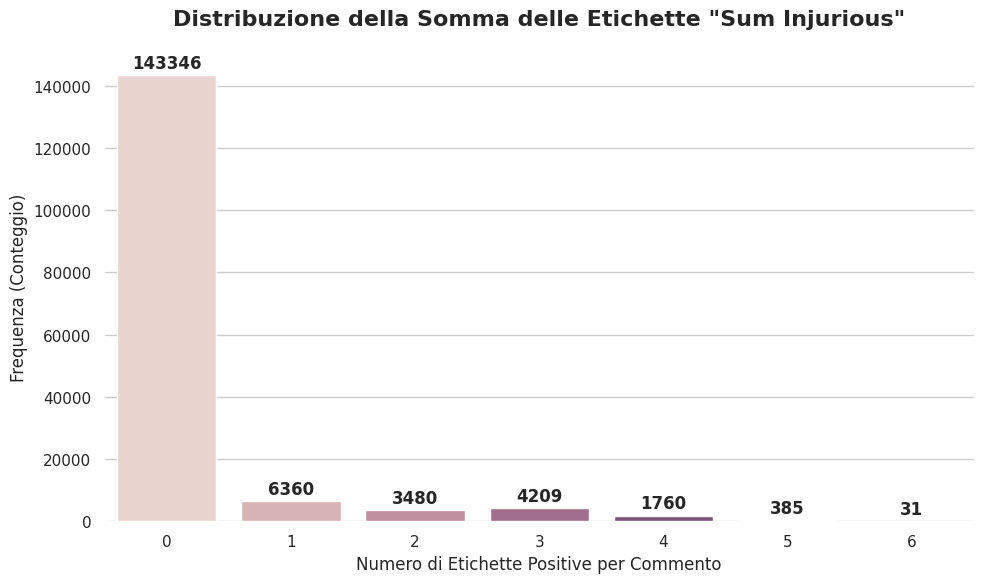

In [ ]:
counts = dataset.sum_injurious.value_counts()

plt.figure(figsize=(10, 6))
sns.set_theme(style='whitegrid', palette='viridis')

# Creazione del barplot
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False)

# 1. Aggiungiamo i valori numerici sopra ogni barra per massima chiarezza
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontsize=12, fontweight='bold')

# 2. Pulizia delle etichette e titoli
plt.title('Distribuzione della Somma delle Etichette "Sum Injurious"', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Numero di Etichette Positive per Commento', fontsize=12)
plt.ylabel('Frequenza (Conteggio)', fontsize=12)

# 3. Ottimizzazione scala e layout
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
sns.despine(left=True, bottom=True) # Rimuove i bordi inutili

plt.tight_layout()
plt.show()

Il dataset è fortemente sbilanciato, sia nella direzione di una grande abbondanza di commenti *non injurious*, sia in una asimettria nella distribuzione tra le label.

Il grafico successivo mostra come siano distribuite le varie label. In particolare *severe_toxic, threat e identity_hate* sono sbilanciate. Dobbiamo sicuramente impostare un meccanismo di pesi che aiuti a bilanciare il dataset; potremo se necessario sviluppare tecniche più aggressive per le label meno numerose.

In [ ]:
non_injurious = dataset[dataset['sum_injurious'] == 0]
injurious = dataset[dataset['sum_injurious'] > 0]

print(f'Il dataset ha {round(len(non_injurious)/len(dataset)*100,2)}% di commenti con connotato positivo e il {round(len(injurious)/len(dataset)*100,2)}% di commenti con connotato negativo')

Il dataset ha 89.83% di commenti con connotato positivo e il 10.17% di commenti con connotato negativo


In [ ]:
categories = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

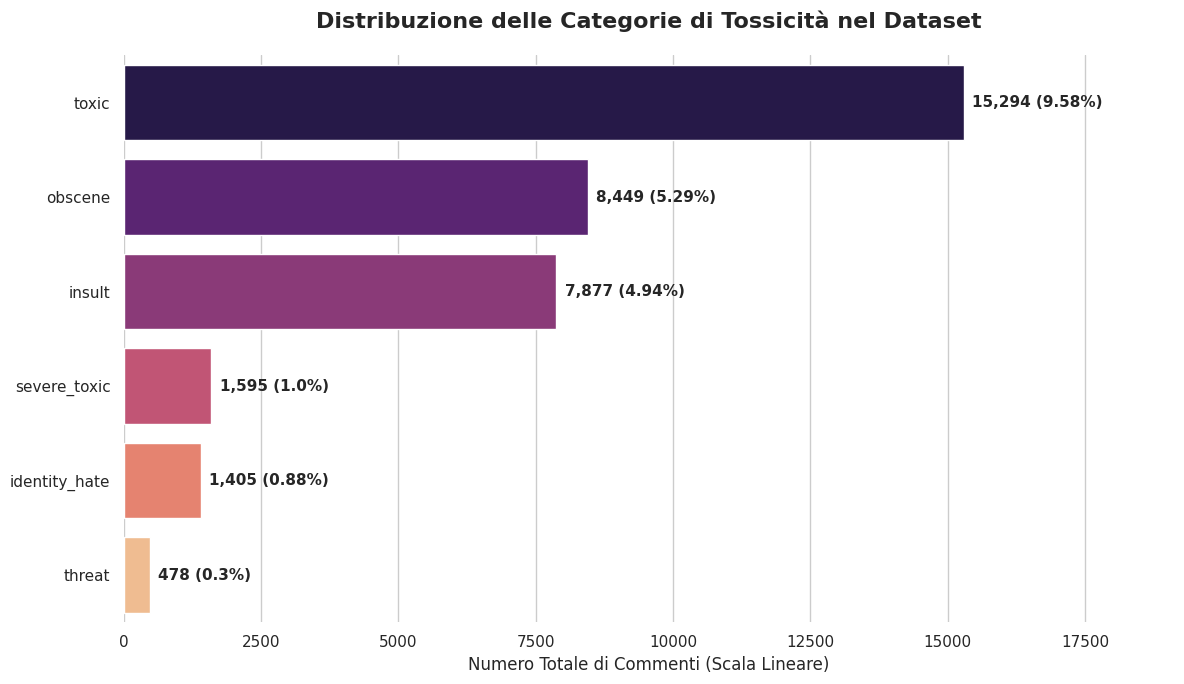

------------------------------
CATEGORIA            |       %
------------------------------
toxic                |    9.58%
obscene              |    5.29%
insult               |    4.94%
severe_toxic         |     1.0%
identity_hate        |    0.88%
threat               |     0.3%


In [ ]:
# 1. Preparazione dati
label_counts = dataset[categories].sum().sort_values(ascending=False)
percentages = (label_counts / len(dataset) * 100).round(2)

# 2. Setup grafico
plt.figure(figsize=(12, 7))
sns.set_theme(style='whitegrid')

# Creazione del barplot orizzontale
ax = sns.barplot(
    x=label_counts.values,
    y=label_counts.index,
    hue=label_counts.index,
    palette='magma',
    legend=False
)

# 3. Aggiunta delle etichette (Valore Assoluto + Percentuale)
for i, (count, pct) in enumerate(zip(label_counts.values, percentages.values)):
    ax.text(
        count + (label_counts.max() * 0.01), # Piccolo offset a destra della barra
        i,
        f'{int(count):,} ({pct}%)',
        va='center',
        fontsize=11,
        fontweight='bold'
    )

# 4. Raffinatezza estetica
plt.title('Distribuzione delle Categorie di Tossicità nel Dataset', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Numero Totale di Commenti (Scala Lineare)', fontsize=12)
plt.ylabel('') # Rimuoviamo l'etichetta dell'asse Y (già chiara dai nomi categorie)

# Espandiamo il limite dell'asse X per far stare i testi
plt.xlim(0, label_counts.max() * 1.25)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

# 5. Tabella stampata (opzionale se hai le etichette sul grafico)
print("-" * 30)
print(f"{'CATEGORIA':<20} | {'%':>7}")
print("-" * 30)
for cat, pct in percentages.items():
    print(f"{cat:<20} | {pct:>7}%")

## PULIZIA DEL DATASET

Studiamo e puliamo il dataset per poterlo fornire al modello.

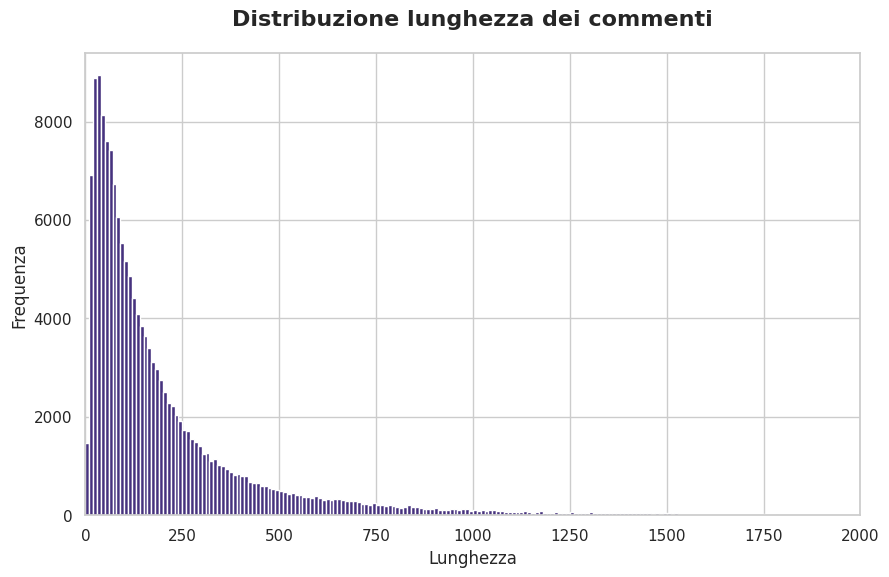


Lunghezza media: 243.61
Lunghezza Mediana: 124.0
Lunghezza Massima: 5000


In [ ]:
sequence_lengths = [len(seq) for seq in dataset['comment_text']]

plt.figure(figsize=(10, 6))
sns.set_theme(style='whitegrid', palette='viridis')

plt.title('Distribuzione lunghezza dei commenti', fontsize=16, pad=20, fontweight='bold')
plt.hist(sequence_lengths, bins=500)
plt.xlabel('Lunghezza')
plt.ylabel('Frequenza')
plt.xlim(0, 2000)
plt.show()

print(f'\nLunghezza media: {np.mean(sequence_lengths):.2f}')
print(f'Lunghezza Mediana: {np.median(sequence_lengths)}')
print(f'Lunghezza Massima: {max(sequence_lengths)}')

In [ ]:
total_txt=''.join(dataset['comment_text'].astype(str)).lower()
words=re.findall(r'\b\w+\b',total_txt)
most_common=Counter(words).most_common()
most_common[:10]

[('the', 496178),
 ('to', 297301),
 ('i', 238246),
 ('of', 224464),
 ('and', 223856),
 ('you', 217485),
 ('a', 215785),
 ('is', 176277),
 ('that', 160623),
 ('it', 148181)]

Il dataset contiene commenti di lunghezza molto variabile e numerose parole non significative per il nostro scopo.
Utilizziamo la libreri *nltk* per pulire il dataset ed eliminare la punteggiatura.

In [ ]:
nltk.download('stopwords')
nltk.download('wordnet')

stop_words_list = set(nltk_stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def text_cleaner(sentence):
    sentence = str(sentence).lower()

    sentence = re.sub(r'[^\w\s]', ' ', sentence)
    sentence = re.sub(r'\d+', '', sentence)

    words = [lemmatizer.lemmatize(word) for word in sentence.split() if word not in stop_words_list]

    return ' '.join(words)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [ ]:
dataset['comment_text'] = dataset['comment_text'].apply(text_cleaner)

In [ ]:
comment_id=min(60, len(dataset))
print(f'Commento iniziale: {copy_ds.comment_text[comment_id]}')
print(f'Commento pulito: {dataset.comment_text[comment_id]}')

Commento iniziale: Locking this page would also violate WP:NEWBIES.  Whether you like it or not, conservatives are Wikipedians too.
Commento pulito: locking page would also violate wp newbie whether like conservative wikipedians


In [ ]:
total_txt=''.join(dataset['comment_text'].astype(str)).lower()
words=re.findall(r'\b\w+\b',total_txt)
most_common=Counter(words).most_common()
most_common[:10]

[('article', 70934),
 ('page', 54461),
 ('wikipedia', 46347),
 ('one', 29503),
 ('talk', 28438),
 ('would', 28436),
 ('like', 27619),
 ('please', 25829),
 ('source', 20745),
 ('see', 20629)]

## PREMODELLO

Una volta pulito il dataset abbiamo deciso di utilizzare un modello prototipo di Logistic Regression per vedere che metriche otteniamo e poter poi valutare i miglioramenti con il modello RNN successivo.
Sappiamo ovviamente che il dataset è fortemente sbilanciato e dovremo affrontare questo punto nella rete neurale successiva.

## LOGISTIC REGRESSION

In [ ]:
categories = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
X_trainLR, X_testLR, y_trainLR, y_testLR = train_test_split(dataset['comment_text'], dataset[categories], test_size=0.2, random_state=42)

# 2. Vettorizzazione (TF-IDF)
vectorizer = TfidfVectorizer(max_features=20000, stop_words='english', ngram_range=(1,2))
X_train_tfidf = vectorizer.fit_transform(X_trainLR)
X_test_tfidf = vectorizer.transform(X_testLR)

# 3. Modello: Logistic Regression pesata per gestire lo sbilanciamento
clf = OneVsRestClassifier(LogisticRegression(class_weight='balanced', solver='liblinear'))
clf.fit(X_train_tfidf, y_trainLR)

OneVsRestClassifier(estimator=LogisticRegression(class_weight='balanced',
                                                 solver='liblinear'))

## Valutazione LR

In [ ]:
# 4. Valutazione
predictions_train = clf.predict(X_train_tfidf)
print('Train set Classification report:')
print(classification_report(y_trainLR, predictions_train, target_names=categories))
print('Test set Classification report:')
predictions_test = clf.predict(X_test_tfidf)
print(classification_report(y_testLR, predictions_test, target_names=categories))

Train set Classification report:
               precision    recall  f1-score   support

        toxic       0.67      0.95      0.78     12238
 severe_toxic       0.30      1.00      0.46      1274
      obscene       0.68      0.98      0.80      6734
       threat       0.28      1.00      0.44       404
       insult       0.57      0.98      0.72      6263
identity_hate       0.27      1.00      0.43      1111

    micro avg       0.57      0.97      0.72     28024
    macro avg       0.46      0.98      0.61     28024
 weighted avg       0.61      0.97      0.74     28024
  samples avg       0.07      0.10      0.08     28024

Test set Classification report:
               precision    recall  f1-score   support

        toxic       0.62      0.85      0.72      3056
 severe_toxic       0.27      0.86      0.41       321
      obscene       0.66      0.88      0.75      1715
       threat       0.16      0.69      0.26        74
       insult       0.53      0.86      0.66      1

**VALUTAZIONI DELLE METRICHE LR**

Possiamo fare due valutazioni sui risultati ottenuti con un semplice modello LR:
- il modello ha dei dati di recall piuttosto buoni, a fronte di dati di precision bassi
- in particolare sulle label *severe_toxic, threat e identity_hate* abbiamo dei crolli di precision a valori molto bassi.

Questo modello LR ci conferma ulteriormente che una dei potenziali problemi ci viene dalla gestione delle classi meno numerose.

# MODELLO LSTM
**Focal Loss:**

La linea di sviluppo del modello che abbiamo scelto è quella di creare una funzione *focal loss* per forzare l'apprendimento del comportamento delle classi più rare, utilizzando due iperparametri:
- più la tua precision è bassa, più alziamo $\gamma$ per forzare il modello a smettere di essere pigro e concentrarsi sui dettagli che trasforma in falsi positivi
- $\alpha$ viene calcolato dinamicamente in base alla rarità reale delle etichette nel dataset.

I due parametri agiscono in maniera combinata in:
$$loss = \alpha_t \cdot (1 - p_t)^\gamma \cdot BCE$$

**Splitting Dataset:**

Dopodichè splittiamo il dataset con *iterative_train_test_split* che ci permette di avere una divisione delle label equilibrata tra addestramento e verifica e lo appiattiamo e tokeniziamo perchè sia pronto per il modello.

**Modello:**

Per la costruzione del modello abbiamo scelto di utilizzare un layer ricorrente bidirezionale LSTM e una concatenzione di *GlobalAveragePooling1D* e *GlobalMaxPooling1D()* per gestire al meglio il significato dei commenti.

**Callbacks:**

Abbiamo definito una rete di funzioni per gestire il fit della rete con un *early stopping* per fermare il modello quando si stabilizza, una *ReduceLROnPlateau* per modificare gli iperparametri di apprendimento quando il modello si avvicina a buoni risultati, ed infine un *Checkpoint* per salvare i migliori parametri del modello.

**Thresholds:**

Abbiamo creato una funzione *find_best_thresholds* per determinare dinamicamente i valori di soglia delle predizione della nostra rete. La funzione analizza ogni classe in maniera seprata ed assegna un thresholds dinamico ad essa.




### PANNELLO IPERPARAMETRI

In [ ]:
# FOCAL LOSS
GAMMA=2.5
ALPHA=0.25

# TEST SPLIT
TEST_SIZE=0.2

# DATASET
MAX_FEATURES=15000
MAXLEN=200

# MODELLO
LEARNING_RATE=1e-3

# CALLBACKS
EARLY_STOP_PATIENCE=3
REDUCE_LR_FACTOR=0.5
REDUCE_LR_PATIENCE=2
REDUCE_LR_MIN_LR=1e-7

# FIT
EPOCHS=10
BATCH_SIZE=48
VALIDATION_SPLIT=0.1

In [ ]:
def focal_loss(gamma=GAMMA, alpha=ALPHA):
    def focal_loss_fixed(y_true, y_pred):
        # 1. Forza y_true e y_pred a float32
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)

        # 2. Forza anche gli iperparametri alpha e gamma a float32
        a = tf.cast(alpha, tf.float32)
        g = tf.cast(gamma, tf.float32)

        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

        # Cross Entropy
        bce = -y_true * tf.math.log(y_pred) - (1 - y_true) * tf.math.log(1 - y_pred)

        # Fattore modulante (pt)
        pt = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)

        # Fattore Alpha
        alpha_factor = tf.where(tf.equal(y_true, 1), a, 1 - a)

        # Calcolo finale con casting esplicito
        loss = alpha_factor * tf.pow(1. - pt, g) * bce

        return tf.reduce_mean(tf.reduce_sum(loss, axis=1))

    return focal_loss_fixed

I weights inizialmente calcolati non vengono più usati in favore della focal loss

In [ ]:
# Trasformiamo in numpy array per la libreria
X = dataset['comment_text'].values.reshape(-1, 1)
y = dataset[categories].values

# Split stratificato (mantiene le proporzioni delle combinazioni di label)
X_train, y_train, X_test, y_test = iterative_train_test_split(X, y, test_size=TEST_SIZE)

# Calcolo dei pesi per la Loss Function (da usare poi nella LSTM)
# Calcoliamo il peso come: (N_campioni) / (2 * N_positivi_nella_classe)
weights = []
for i in range(y.shape[1]):
    count_pos = np.sum(y[:, i])
    weight = len(y) / (2.0 * count_pos)
    weights.append(weight)

print("Pesi suggeriti per la BCE Loss:", dict(zip(categories, weights)))

Pesi suggeriti per la BCE Loss: {'toxic': np.float64(5.216784359879691), 'severe_toxic': np.float64(50.02225705329153), 'obscene': np.float64(9.443188543022844), 'threat': np.float64(166.9152719665272), 'insult': np.float64(10.128919639456646), 'identity_hate': np.float64(56.78683274021353)}


Appiattiamo, tokeniziamo ed effettuiamo il padding sui commenti in input nella variabile X.

In [ ]:
# Parametri
max_features = MAX_FEATURES
maxlen = MAXLEN

# Forza i dati ad essere una lista piatta di stringhe
X_train_flat = np.array(X_train).flatten().astype(str)
X_test_flat = np.array(X_test).flatten().astype(str)

# Tokenizer
tokenizer = Tokenizer(num_words=max_features)
tokenizer.fit_on_texts(list(X_train_flat))

# Trasforma in sequenze
X_train_seq = tokenizer.texts_to_sequences(X_train_flat)
X_test_seq = tokenizer.texts_to_sequences(X_test_flat)

# Padding
X_train_pad = pad_sequences(X_train_seq, maxlen=maxlen)
X_test_pad = pad_sequences(X_test_seq, maxlen=maxlen)

## RETE NEURALE

Costruiamo la rete utilizzando i seguenti strati:
- **Inizializzazione Embedding:**
Il layer Embedding converte i numeri dei token in vettori densi di 128 dimensioni. Qui il modello impara le relazioni tra le parole (es. "insulto" vicino a "offesa").

- **Bidirectional LSTM:**
Usando Bidirectional, il modello legge la frase da sinistra a destra e viceversa. Questo è fondamentale per capire il sarcasmo o le negazioni (es. "Non sei intelligente" vs "Sei intelligente").

- **Global Avarage Pooling:**
Calcola la media di tutti i vettori prodotti dalla LSTM lungo la sequenza temporale (le parole del commento). Serve a capire il sentiment generale o il tono complessivo del discorso.

- **Global Max Pooling:**
Invece di usare solo l'ultimo stato della LSTM, il GlobalMaxPool1D estrae il valore massimo per ogni feature lungo l'intera frase, catturando i segnali di "tossicità" più forti ovunque si trovino.

- **Classificazione Multi-label:**
Il layer finale con 6 neuroni usa la funzione Sigmoid. A differenza della Softmax, la Sigmoid permette di attivare più classi contemporaneamente, identificando se un commento è sia Toxic che Insult.

In [ ]:
def build_advanced_model(max_features, maxlen):
    clear_session()
    input_layer = Input(shape=(maxlen,))

    # Inizializziamo con GloVe, ma lasciamo trainable=True per fine-tuning
    x = Embedding(max_features, 100)(input_layer)
    x = SpatialDropout1D(0.4)(x) # Aumentato a 0.4 per contrastare l'overfitting

    # Layer Ricorrente
    x = Bidirectional(LSTM(128, return_sequences=True))(x)

    # Double Pooling Strategy
    avg_pool = GlobalAveragePooling1D()(x)
    max_pool = GlobalMaxPooling1D()(x)
    concatenated = Concatenate()([avg_pool, max_pool])

    # Head del classificatore
    x = Dense(64, activation='relu')(concatenated)
    x = Dropout(0.5)(x)
    output = Dense(6, activation='sigmoid')(input_layer if False else x) # Corretto l'input dell'output layer

    model = Model(inputs=input_layer, outputs=output)
    return model

In [ ]:
# Compilazione
model = build_advanced_model(max_features, maxlen)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), # LR più alto all'inizio grazie a ReduceLROnPlateau
    loss=focal_loss(gamma=GAMMA, alpha=ALPHA),
    metrics=[tf.keras.metrics.AUC(name='pr_auc', curve='PR')]
)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 100)  │  1,500,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 200, 100)  │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 200, 256)  │    234,496 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 256)       │          0 │ bidirectional[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 256)       │          0 │ bidirectional[0]… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 512)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     32,832 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 6)         │        390 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,767,718 (6.74 MB)

 Trainable params: 1,767,718 (6.74 MB)

 Non-trainable params: 0 (0.00 B)

### CALLBACK LIST
Definiamo tre funzioni per monitorare l'andamento dell'addestramento:
- **early stopping:** ferma l'addestramento se *val_loss* smette di scendere dopo due epoche di addestramento

- **reduce_lr:** riduce il learning rate nel momento in cui ci avviciniamo ai minimi del gradient descent

- **checkopoint:** salva il modello contentete i migliori pesi al termine di ogni epoca, sovrascrivendo solo in caso di miglioramento

In [ ]:
# 1. Early Stopping: Più respiro per gestire la severità della Focal Loss
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=EARLY_STOP_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

# 2. Reduce LR: Una discesa più dolce aiuta l'LSTM a rifinire i pesi
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=REDUCE_LR_FACTOR,
    patience=REDUCE_LR_PATIENCE,
    min_lr=REDUCE_LR_MIN_LR,
    verbose=1
)

# 3. Checkpoint:
checkpoint = ModelCheckpoint(
    'best_model_focal.keras',
    monitor='val_loss',
    save_best_only=True
)

callbacks_list = [early_stop, reduce_lr, checkpoint]

### ADDESTRAMENTO

In [ ]:
class_weights_dict = {i: weights[i] for i in range(len(categories))}

history = model.fit(
    X_train_pad, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    # class_weight=class_weights_dict,
    callbacks=callbacks_list
    )

Epoch 1/10
2394/2394 ━━━━━━━━━━━━━━━━━━━━ 2009s 837ms/step - loss: 0.0319 - pr_auc: 0.6462 - val_loss: 0.0405 - val_pr_auc: 0.8257 - learning_rate: 0.0010
Epoch 2/10
2394/2394 ━━━━━━━━━━━━━━━━━━━━ 1943s 812ms/step - loss: 0.0213 - pr_auc: 0.8047 - val_loss: 0.0396 - val_pr_auc: 0.8295 - learning_rate: 0.0010
Epoch 3/10
2394/2394 ━━━━━━━━━━━━━━━━━━━━ 1938s 810ms/step - loss: 0.0194 - pr_auc: 0.8278 - val_loss: 0.0420 - val_pr_auc: 0.8320 - learning_rate: 0.0010
Epoch 4/10
2394/2394 ━━━━━━━━━━━━━━━━━━━━ 0s 787ms/step - loss: 0.0175 - pr_auc: 0.8517
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
2394/2394 ━━━━━━━━━━━━━━━━━━━━ 1967s 821ms/step - loss: 0.0179 - pr_auc: 0.8468 - val_loss: 0.0405 - val_pr_auc: 0.8333 - learning_rate: 0.0010
Epoch 5/10
2394/2394 ━━━━━━━━━━━━━━━━━━━━ 1969s 808ms/step - loss: 0.0159 - pr_auc: 0.8724 - val_loss: 0.0475 - val_pr_auc: 0.8324 - learning_rate: 5.0000e-04
Epoch 5: early stopping
Restoring model weights from the end of the 

In [ ]:
model = load_model(
    'best_model_focal.keras',
    custom_objects={'focal_loss_fixed': focal_loss}
)

Metriche disponibili: ['loss', 'pr_auc', 'val_loss', 'val_pr_auc', 'learning_rate']


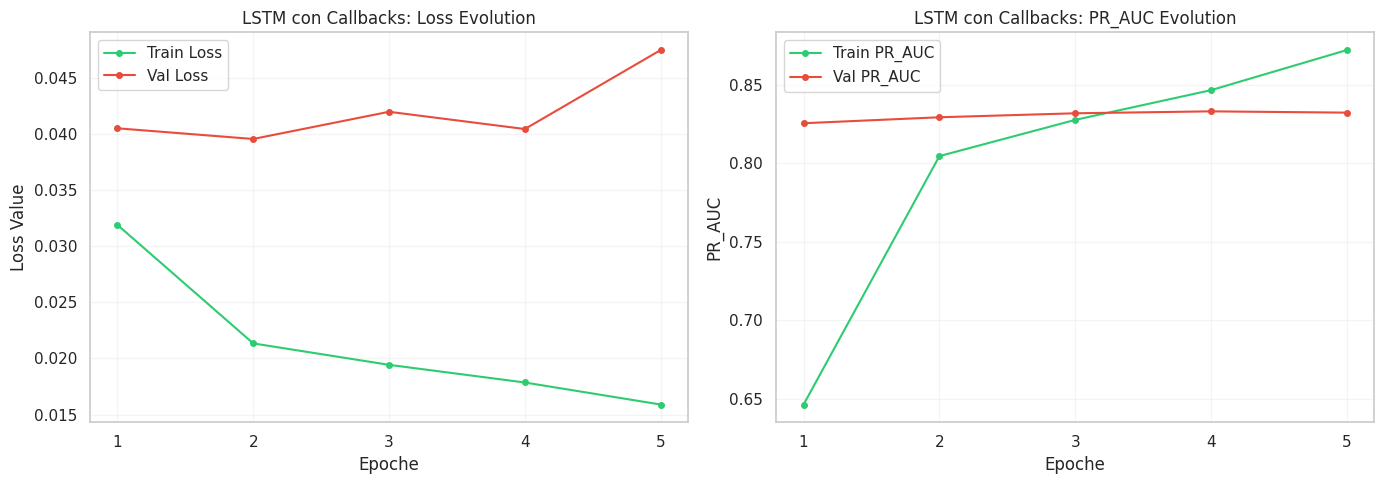

In [ ]:
plot_learning_curves(history, "LSTM con Callbacks")

In [ ]:
def find_best_thresholds(y_true, y_pred_probs, categories):
    best_thresholds = {}
    for i, cat in enumerate(categories):
        # Calcoliamo precision, recall e thresholds per la singola classe
        precision, recall, thresholds = precision_recall_curve(y_true[:, i], y_pred_probs[:, i])

        # Calcoliamo l'F1-score per ogni threshold
        # Usiamo un piccolo epsilon per evitare divisioni per zero
        f1_scores = (2 * precision * recall) / (precision + recall + 1e-8)

        # Troviamo l'indice del miglior F1-score
        best_idx = np.argmax(f1_scores)
        best_thresholds[cat] = thresholds[best_idx]

        print(f"Classe: {cat:15} | Best Threshold: {thresholds[best_idx]:.4f} | F1-Score: {f1_scores[best_idx]:.4f}")

    return best_thresholds

In [ ]:
# 1. Otteniamo le probabilità
y_pred_probs = model.predict(X_test_pad)

# 2. Calcolo i threshold ottimali
best_thresholds_dict = find_best_thresholds(y_test, y_pred_probs, categories)

# 3. Applico ogni threshold alla relativa colonna
y_pred_bin = np.zeros_like(y_pred_probs)
for i, cat in enumerate(categories):
    threshold = best_thresholds_dict[cat]
    y_pred_bin[:, i] = (y_pred_probs[:, i] >= threshold).astype(int)

print("\n--- Report Test Set ---")
print(classification_report(y_test, y_pred_bin, target_names=categories))

998/998 ━━━━━━━━━━━━━━━━━━━━ 188s 188ms/step
Classe: toxic           | Best Threshold: 0.3880 | F1-Score: 0.7996
Classe: severe_toxic    | Best Threshold: 0.3226 | F1-Score: 0.4958
Classe: obscene         | Best Threshold: 0.3992 | F1-Score: 0.7976
Classe: threat          | Best Threshold: 0.2458 | F1-Score: 0.1786
Classe: insult          | Best Threshold: 0.3797 | F1-Score: 0.7068
Classe: identity_hate   | Best Threshold: 0.2884 | F1-Score: 0.3232

--- Report Test Set ---
               precision    recall  f1-score   support

        toxic       0.84      0.77      0.80      3059
 severe_toxic       0.40      0.65      0.50       319
      obscene       0.81      0.78      0.80      1690
       threat       0.14      0.26      0.18        96
       insult       0.67      0.74      0.71      1575
identity_hate       0.23      0.57      0.32       281

    micro avg       0.69      0.75      0.72      7020
    macro avg       0.51      0.63      0.55      7020
 weighted avg       0.74 

In [ ]:
# 2. Genera il dizionario delle metriche
report_dict = classification_report(
    y_test,
    y_pred_bin,
    target_names=categories,
    output_dict=True  # FONDAMENTALE per ottenere il dizionario
)

## FINE TUNING

Per aumentare l'efficacia del modello proviamo a fare un fine tuning su un sub dataset ribilanciato sulle classi meno numerose.
Per farlo abbiamo creato la funzione *create_lean_balanced_set* che crea un dataset bilanciato secondo l'iperparametro *majority ratio*.

Per il processo di fine tuning abbiamo creato una funzione *get dynamic hyperparameters* che calcola i valori di $\alpha$ e $\gamma$ in maniera dinamica correggendo i bias della fase di training.

Nel riaddestramento teniamo congelato il layer embedding e viene utilizzato un *learning rate* più basso rispetto al training principale

### PANNELLO IPERPARAMETRI FINE TUNING

In [ ]:
# SUBDATASET
MAJORITY_RATIO=2.0

# TUNING
FT_LEARNING_RATE=1e-5

# FIT
FT_EPOCHS=10
FT_BATCH_SIZE=16
FT_VALIDATION_SPLIT=0.2

In [ ]:
def create_lean_balanced_set(X, y, categories, majority_ratio=MAJORITY_RATIO):

    # 1. Identificazione classi rare (sotto la mediana)
    class_counts = np.sum(y, axis=0)
    median_freq = np.median(class_counts)
    rare_indices_cols = np.where(class_counts < median_freq)[0]

    # 2. Indici dei campioni rari (da tenere TUTTI)
    rare_mask = np.any(y[:, rare_indices_cols] == 1, axis=1)
    rare_samples_idx = np.where(rare_mask)[0]

    # 3. Indici dei campioni comuni (da sottocampionare)
    common_samples_idx = np.where(~rare_mask)[0]

    # Calcoliamo quanti campioni comuni tenere per non sbilanciare troppo
    # Se majority_ratio=1.0, avremo 50% rari e 50% comuni.
    n_common_to_keep = int(len(rare_samples_idx) * majority_ratio)

    # Selezione casuale dei comuni
    selected_common_idx = np.random.choice(
        common_samples_idx,
        size=min(len(common_samples_idx), n_common_to_keep),
        replace=False
    )

    # 4. Unione e Shuffle
    final_indices = np.concatenate([rare_samples_idx, selected_common_idx])
    np.random.shuffle(final_indices)

    X_ft = X[final_indices]
    y_ft = y[final_indices]

    print(f"--- Fine-Tuning Lean Dataset ---")
    print(f"Esempi Rari mantenuti: {len(rare_samples_idx)}")
    print(f"Esempi Comuni selezionati: {len(selected_common_idx)}")
    print(f"Dimensione totale FT: {len(X_ft)} (vs {len(X)} originali)")

    return X_ft, y_ft

In [ ]:
X_ft, y_ft = create_lean_balanced_set(X_train_pad, y_train, categories)

--- Fine-Tuning Lean Dataset ---
Esempi Rari mantenuti: 2390
Esempi Comuni selezionati: 4780
Dimensione totale FT: 7170 (vs 127656 originali)


In [ ]:
def get_dynamic_hyperparameters(y_ft, report_dict):
    # Trasformiamo in array numpy
    y_ft = np.array(y_ft)

    # 1. Calcolo Alpha per dati Multi-Label
    # Calcoliamo la media della presenza di classi positive su tutte le etichette
    # Se y_ft ha forma (n_samples, 6), calcoliamo quanti 1 ci sono in totale
    total_positives = np.sum(y_ft)
    total_elements = y_ft.size

    # Alpha basato sulla rarità media dei positivi nel dataset
    alpha = 1 - (total_positives / total_elements)

    # 2. Calcolo Gamma basato sulla Precision (invariato)
    mean_precision = report_dict['macro avg']['precision']

    if mean_precision < 0.4:
        gamma = 3.0
    elif mean_precision < 0.6:
        gamma = 2.0
    else:
        gamma = 1.5

    return alpha, gamma

In [ ]:
# --- FASE 2: SETUP FINE-TUNING ---
# Usiamo y_train per alpha (rarità vera) e report_dict per gamma (difficoltà appresa)
alpha_ft, gamma_ft = get_dynamic_hyperparameters(y_train, report_dict)

model.layers[0].trainable = False # Embedding congelato
model.compile(
    loss=focal_loss(alpha=alpha_ft, gamma=gamma_ft),
    optimizer=Adam(learning_rate=FT_LEARNING_RATE),
    metrics=['AUC']
)


In [ ]:
# --- FASE 3: TRAINING ---
history_ft = model.fit(
    X_ft, y_ft,
    epochs=FT_EPOCHS,
    batch_size=FT_BATCH_SIZE,
    validation_split=FT_VALIDATION_SPLIT,
    callbacks=callbacks_list,
    verbose=1
)

Epoch 1/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 146s 390ms/step - AUC: 0.9633 - loss: 0.3855 - val_AUC: 0.9702 - val_loss: 0.3314 - learning_rate: 1.0000e-05
Epoch 2/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 366ms/step - AUC: 0.9625 - loss: 0.3497
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
359/359 ━━━━━━━━━━━━━━━━━━━━ 142s 395ms/step - AUC: 0.9631 - loss: 0.3402 - val_AUC: 0.9685 - val_loss: 0.2999 - learning_rate: 1.0000e-05
Epoch 3/10
359/359 ━━━━━━━━━━━━━━━━━━━━ 139s 387ms/step - AUC: 0.9625 - loss: 0.3158 - val_AUC: 0.9676 - val_loss: 0.2885 - learning_rate: 5.0000e-06
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.


In [ ]:
# --- FASE 4: RICALCOLO THRESHOLDS ---
y_pred_probs_final = model.predict(X_test_pad)

# Questa è la funzione che abbiamo definito prima
best_thresholds_new = find_best_thresholds(y_test, y_pred_probs_final, categories)

# Applichiamo i nuovi threshold
y_pred_bin_final = np.zeros_like(y_pred_probs_final)
for i, cat in enumerate(categories):
    y_pred_bin_final[:, i] = (y_pred_probs_final[:, i] >= best_thresholds_new[cat]).astype(int)

# Report Finale
print("--- REPORT FINALE POST FINE-TUNING E RICALIBRAZIONE ---")
print(classification_report(y_test, y_pred_bin_final, target_names=categories))

998/998 ━━━━━━━━━━━━━━━━━━━━ 188s 188ms/step
Classe: toxic           | Best Threshold: 0.4157 | F1-Score: 0.7997
Classe: severe_toxic    | Best Threshold: 0.3573 | F1-Score: 0.4850
Classe: obscene         | Best Threshold: 0.4093 | F1-Score: 0.8023
Classe: threat          | Best Threshold: 0.2643 | F1-Score: 0.1481
Classe: insult          | Best Threshold: 0.4022 | F1-Score: 0.7080
Classe: identity_hate   | Best Threshold: 0.3170 | F1-Score: 0.3234
--- REPORT FINALE POST FINE-TUNING E RICALIBRAZIONE ---
               precision    recall  f1-score   support

        toxic       0.81      0.79      0.80      3059
 severe_toxic       0.40      0.61      0.48       319
      obscene       0.77      0.84      0.80      1690
       threat       0.11      0.21      0.15        96
       insult       0.66      0.77      0.71      1575
identity_hate       0.27      0.41      0.32       281

    micro avg       0.69      0.76      0.73      7020
    macro avg       0.50      0.60      0.54     

## CONFRONTO METRICHE


In [ ]:
print('Logistic Regression')
print(classification_report(y_testLR, predictions_test, target_names=categories))

print("\nModello LSTM")
print(classification_report(y_test, y_pred_bin, target_names=categories))

print("\nModello dopo Fine Tuning")
print(classification_report(y_test, y_pred_bin_final, target_names=categories))

Logistic Regression
               precision    recall  f1-score   support

        toxic       0.62      0.85      0.72      3056
 severe_toxic       0.27      0.86      0.41       321
      obscene       0.66      0.88      0.75      1715
       threat       0.16      0.69      0.26        74
       insult       0.53      0.86      0.66      1614
identity_hate       0.22      0.77      0.34       294

    micro avg       0.53      0.85      0.65      7074
    macro avg       0.41      0.82      0.52      7074
 weighted avg       0.57      0.85      0.68      7074
  samples avg       0.06      0.08      0.07      7074


Modello LSTM
               precision    recall  f1-score   support

        toxic       0.84      0.77      0.80      3059
 severe_toxic       0.40      0.65      0.50       319
      obscene       0.81      0.78      0.80      1690
       threat       0.14      0.26      0.18        96
       insult       0.67      0.74      0.71      1575
identity_hate       0.23   

# CONCLUSIONI

Possiamo fare alcune valutazioni sui modelli costruiti e sui risultati ottenuti.

Siamo partiti costruendo una **Regressione Logistica** le cui metriche mostrano una recall molto alta ma una precision complessiva bassa (*macro avg*). Questo perchè la dipendenza lineare della LR non è in grado di modellizzare correttamente il significato della frase ma resta legato al peso di singole parole.

Il **Modello LSTM** mostra un significativo passo in avanti in questa direzione (*weighted avg precision=0.74*) e pur perdendo lievissimamente in recall è un modello molto più affidabile.

Dopo il **Fine Tuning** le metriche complessive restano simili al modello precedente, ma possiamo considerarci soddisfatti di essere riusciti a bilanciare meglio gli errori tra le classi.
Resta evidente il fatto che sulle classi più rare il modello faccia fatica, ed in particolare su *Threat* è evidente che un grosso problema è dovuto alla mancanza di dati (con 96 osservazioni il fine tuning è comunque insufficiente).

Per migliorare e rafforzare ulteriormente il modello ci sono varie opzioni che possiamo intreprendere:
- data augmentation per le classi rare usando un procedimento di back translation
- utilizzare anche la funzione weights che abbiamo definito e tenuto in sospeso
- Utilizzare modelli di base preaddestrati su cui specializzare il nostro modello.

Per l'obiettivo che ci eravamo dati possiamo ritenerci soddisfatti dei risultati ottenuti.

## APPLICAZIONE A CAMPIONE

Creiamo una funzione rapida di test visivo che mostra il comportamento del modello su frasi casuali del dataset.

In [ ]:
def inspect_random_samples(model, X_test_pad, y_test, df_original, categories, thresholds_dict, n_examples=10):

    # 1. Selezione casuale
    random_indices = random.sample(range(len(X_test_pad)), n_examples)

    X_sample = X_test_pad[random_indices]
    y_true_sample = y_test[random_indices]

    # 2. Predizione (Probabilità)
    probs = model.predict(X_sample)

    print(f"=== ISPEZIONE CASUALE ({n_examples} ESEMPI) ===\n")
    print(f"Nota: Utilizzo thresholds dinamici post-Focal Loss\n")

    for i, idx in enumerate(random_indices):
        # Recupero del testo originale
        raw_text = df_original.iloc[idx]['comment_text']

        print(f"ESEMPIO {i+1} (Indice Test Set: {idx}):")
        print(f"\"{raw_text[:250]}...\"" if len(raw_text) > 250 else f"\"{raw_text}\"")

        results = []
        for j, cat in enumerate(categories):
            prob = probs[i][j]
            # Recuperiamo la soglia specifica per questa categoria
            thresh = thresholds_dict[cat]

            # Predizione binaria basata sulla soglia specifica
            pred_bin = 1 if prob >= thresh else 0
            true_bin = int(y_true_sample[i][j])

            # Match check
            is_match = "✅" if true_bin == pred_bin else "❌"
            #if true_bin == 1 and pred_bin == 1: is_match = "🔥 (CORRETTO POSITIVO)"

            results.append({
                'Categoria': f"{cat:15}",
                'Reale': true_bin,
                'Predetto': pred_bin,
                'Prob %': f"{prob*100:5.1f}%",
                'Soglia Usata': f"{thresh:.4f}",
                'Esito': is_match
            })

        # Visualizzazione tabellare per l'esempio corrente
        print(pd.DataFrame(results).to_string(index=False))
        print("-" * 80 + "\n")

In [ ]:
inspect_random_samples(model, X_test_pad, y_test, dataset, categories, best_thresholds_new)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
=== ISPEZIONE CASUALE (10 ESEMPI) ===

Nota: Utilizzo thresholds dinamici post-Focal Loss

ESEMPIO 1 (Indice Test Set: 11470):
"hêbê debate european parliament wikipedia truth consensus oreo priest see prolific wikipedia editor live brussels chance ask debate planned usefulness reliability wikipedia european parliament brussels monday evening september th interested either de..."
      Categoria  Reale  Predetto Prob % Soglia Usata Esito
toxic                0         0   7.0%       0.4157     ✅
severe_toxic         0         0   0.2%       0.3573     ✅
obscene              0         0   2.1%       0.4093     ✅
threat               0         0   0.8%       0.2643     ✅
insult               0         0   3.6%       0.4022     ✅
identity_hate        0         0   1.5%       0.3170     ✅
--------------------------------------------------------------------------------

ESEMPIO 2 (Indice Test Set: 20397):
"hot rape"
      Categoria  Reale  Predetto Pro